<center><h1>Zuo_Xiyi_HW7</h1></center>
<br>
<center><font size="4">Multi-label SVMs and K-Means on Anuran Calls, and ISLR 12.6.2</font></center>

**Name:** Xiyi Zuo

**GitHub Username:** Kiera111

**USC ID:** 9330953458


## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

### Package imports

All dependencies are imported in the next cell so the notebook can be run from a clean kernel with Run All.


In [1]:
%matplotlib inline

import os
import time
import warnings

os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count() or 1)
warnings.filterwarnings(
    "ignore",
    message="Could not find the number of physical cores",
)

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from joblib import Parallel, delayed
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.cluster import KMeans
from sklearn.metrics import balanced_accuracy_score, recall_score, silhouette_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 552
DATA_PATH = Path("../data/Frogs_MFCCs.csv")
LABEL_COLS = ["Family", "Genus", "Species"]
CV = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
# Log-spaced penalty weights. In sklearn this is C, the weight on the hinge loss.
C_GRID = np.logspace(-1, 3, 5)
# Linearly spaced Gaussian widths. sklearn uses gamma = 1 / (2 * sigma^2).
SIGMA_GRID = np.linspace(0.2, 2.0, 5)
GAMMA_GRID = 1.0 / (2.0 * SIGMA_GRID**2)
# After standardization the features have variance 1, so the kernel width is retuned on gamma directly.
SCALED_GAMMA_GRID = np.logspace(-2, 1, 5)
L1_C_GRID = np.logspace(-2, 3, 6)


### (a) Download the Anuran Calls (MFCCs) Data Set

The file used here is the UCI Anuran Calls (MFCCs) data set. Relative to this notebook it is `../data/Frogs_MFCCs.csv`. Each row is one syllable. The 22 MFCC columns are the features. `Family`, `Genus`, and `Species` are three labels for the same syllable. `RecordID` identifies the source recording and is not used as a feature.

Seventy percent of the rows are drawn at random for training. The remaining thirty percent are the test set. The same split is used for every label.


rows: 7195
features: 22
missing values: 0
feature min: -0.9523   feature max: 1.0000
training rows: 5036   test rows: 2159

Family


,count
Family,
Leptodactylidae,4420
Hylidae,2165
Dendrobatidae,542
Bufonidae,68


Genus


,count
Genus,
Adenomera,4150
Hypsiboas,1593
Ameerega,542
Dendropsophus,310
Leptodactylus,270
Scinax,148
Osteocephalus,114
Rhinella,68


Species


,count
Species,
AdenomeraHylaedactylus,3478
HypsiboasCordobae,1121
AdenomeraAndre,672
Ameeregatrivittata,542
HypsiboasCinerascens,472
HylaMinuta,310
LeptodactylusFuscus,270
ScinaxRuber,148
OsteocephalusOophagus,114


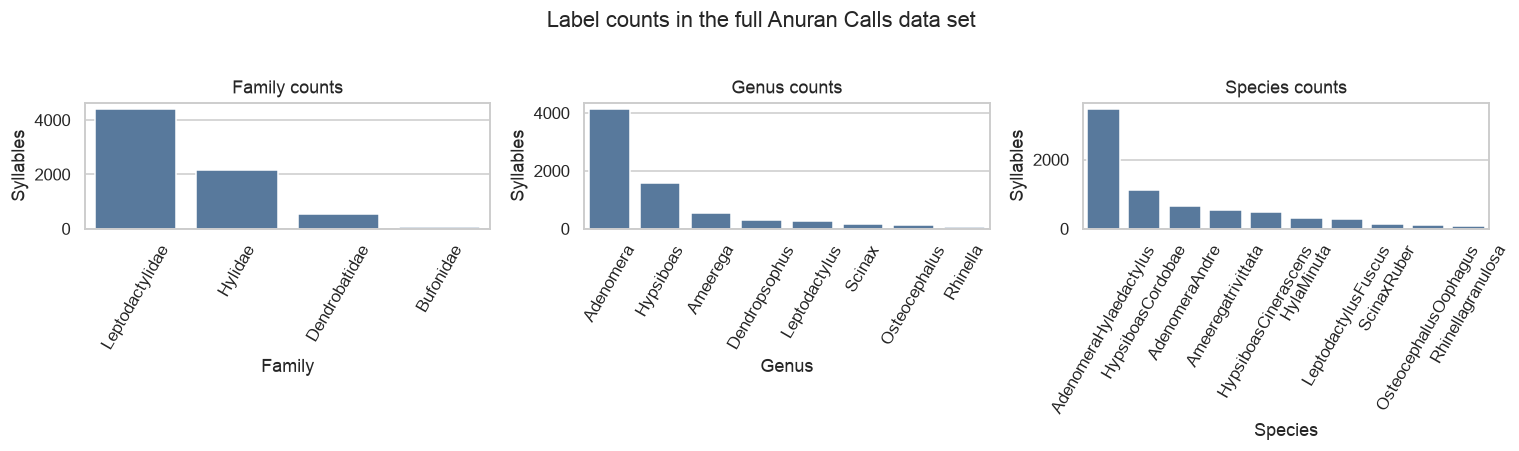

smallest class count inside the training split: 48


In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Expected ../data/Frogs_MFCCs.csv. Run this notebook from the notebook directory."
    )

frogs = pd.read_csv(DATA_PATH)
feature_cols = [column for column in frogs.columns if column.startswith("MFCCs")]
if len(feature_cols) != 22:
    raise ValueError(f"Expected 22 MFCC columns, found {len(feature_cols)}.")

X = frogs[feature_cols].to_numpy(dtype=float)
Y = frogs[LABEL_COLS].copy()
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.3, random_state=RANDOM_STATE
)
Y_train_np = Y_train.to_numpy()
Y_test_np = Y_test.to_numpy()

print(f"rows: {len(frogs)}")
print(f"features: {len(feature_cols)}")
print(f"missing values: {int(frogs.isna().sum().sum())}")
print(f"feature min: {X.min():.4f}   feature max: {X.max():.4f}")
print(f"training rows: {len(X_train)}   test rows: {len(X_test)}")
print()

for column in LABEL_COLS:
    print(column)
    display(frogs[column].value_counts().rename("count").to_frame())

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, column in zip(axes, LABEL_COLS):
    order = frogs[column].value_counts()
    sns.barplot(x=order.index.astype(str), y=order.values, ax=ax, color="#4C78A8")
    ax.set_title(f"{column} counts")
    ax.set_xlabel(column)
    ax.set_ylabel("Syllables")
    ax.tick_params(axis="x", rotation=60)
fig.suptitle("Label counts in the full Anuran Calls data set", y=1.02)
fig.tight_layout()
plt.show()

smallest_train_class = int(min(Y_train[column].value_counts().min() for column in LABEL_COLS))
print(f"smallest class count inside the training split: {smallest_train_class}")
if smallest_train_class < CV.n_splits:
    raise RuntimeError("A training class has fewer rows than the number of CV folds.")


### (b) Train a classifier for each label

Each syllable has three labels, and each label has more than two classes. The model below is binary relevance: one multi-class classifier is trained for Family, another for Genus, and another for Species. The three predictions are then scored together.

#### (i) Research

Two multi-label summaries are used for every classifier in this problem.

**Exact match** (subset accuracy) is the fraction of syllables for which Family, Genus, and Species are all correct. One wrong label makes the syllable count as a miss. This is a strict measure of whether the whole label triplet is recovered.

**Hamming loss** is the fraction of individual labels that are wrong. A syllable with only the genus wrong contributes one third, not a total miss. With `L = 3` labels and `N` test syllables,

`Hamming loss = (1 / (N L)) * (number of wrong labels)`.

**Hamming score** is `1 - Hamming loss`, the fraction of individual labels that are correct.

**Hamming distance**, as reported in this notebook, is the average number of wrong labels per syllable. It equals `3 * Hamming loss` and lies between 0 and 3. Exact match, Hamming score, and Hamming loss answer different questions, so a model can look strong on Hamming loss and weaker on exact match when its mistakes are spread across syllables.

These definitions follow the multi-label evaluation survey of Sorower (2010). Hamming loss is the same quantity as `sklearn.metrics.hamming_loss`.


In [3]:
def multilabel_report(name, y_true, y_pred):
    """Exact match and Hamming summaries for a three-label prediction."""
    mismatches = y_true != y_pred
    hamming_loss = float(mismatches.mean())
    row = {
        "model": name,
        "exact_match": float((~mismatches.any(axis=1)).mean()),
        "hamming_distance": float(mismatches.sum(axis=1).mean()),
        "hamming_score": float(1.0 - hamming_loss),
        "hamming_loss": hamming_loss,
    }
    balanced = []
    for index, label in enumerate(LABEL_COLS):
        accuracy = float((y_true[:, index] == y_pred[:, index]).mean())
        balanced_accuracy = float(
            balanced_accuracy_score(y_true[:, index], y_pred[:, index])
        )
        row[f"{label}_accuracy"] = accuracy
        row[f"{label}_balanced_accuracy"] = balanced_accuracy
        balanced.append(balanced_accuracy)
    row["mean_balanced_accuracy"] = float(np.mean(balanced))
    return pd.Series(row)


def show_metrics(report):
    display(report.to_frame(name="value"))


#### (ii) Train a SVM for each of the labels

Each label gets a Gaussian-kernel SVM trained with the one-versus-all strategy. scikit-learn's `SVC` solves a multi-class problem with one-versus-one, so it is wrapped in `OneVsRestClassifier`. That wrapper trains one binary Gaussian SVM per class, using all training rows in each binary problem.

The kernel implemented by scikit-learn is `exp(-gamma ||x - x'||^2)`. The width `sigma` in the homework is tied to that parameter by `gamma = 1 / (2 sigma^2)`. The penalty weight searched here is scikit-learn's `C`, the weight on the hinge loss, on a log grid. `sigma` is searched on a linear grid from 0.2 to 2, which is the kind of range suggested in the homework footnote. Both grids have five values. The selected pair for each label is the one with the highest mean accuracy under 10-fold stratified cross-validation. The selected classifier is then refit on the full training split and scored on the held-out 30 percent.

The MFCCs are already scaled to about [-1, 1]. The first block below uses those raw attributes. The second block standardizes them inside each cross-validation fold and retunes `gamma`, because standardization changes pairwise distances and the original `sigma` grid would no longer sit on the same scale.


Training accuracy at the four corners of the raw (C, sigma) grid


,label,C,sigma,training_accuracy
0,Family,0.1,0.2,0.9905
1,Family,0.1,2.0,0.8803
2,Family,1000.0,0.2,1.0000
3,Family,1000.0,2.0,0.9978
4,Genus,0.1,0.2,0.9817
5,Genus,0.1,2.0,0.8767
6,Genus,1000.0,0.2,1.0000
7,Genus,1000.0,2.0,0.9992
8,Species,0.1,0.2,0.9948
9,Species,0.1,2.0,0.8691


Every corner is at or above the 70% training-accuracy threshold from the footnote.


raw Family: C=100, sigma=0.650, CV accuracy=0.9923, 10.0s


raw Genus: C=10, sigma=0.650, CV accuracy=0.9905, 13.3s


raw Species: C=100, sigma=0.650, CV accuracy=0.9899, 14.5s

Selected raw Gaussian hyperparameters


,C,gamma,sigma,mean_cv_accuracy
label,,,,
Family,100.0,1.1834,0.65,0.9923
Genus,10.0,1.1834,0.65,0.9905
Species,100.0,1.1834,0.65,0.9899


Test metrics, raw Gaussian one-vs-all SVM


,value
model,Gaussian raw
exact_match,0.9838
hamming_distance,0.0315
hamming_score,0.9895
hamming_loss,0.0105
Family_accuracy,0.9907
Family_balanced_accuracy,0.97
Genus_accuracy,0.9903
Genus_balanced_accuracy,0.9652
Species_accuracy,0.9875


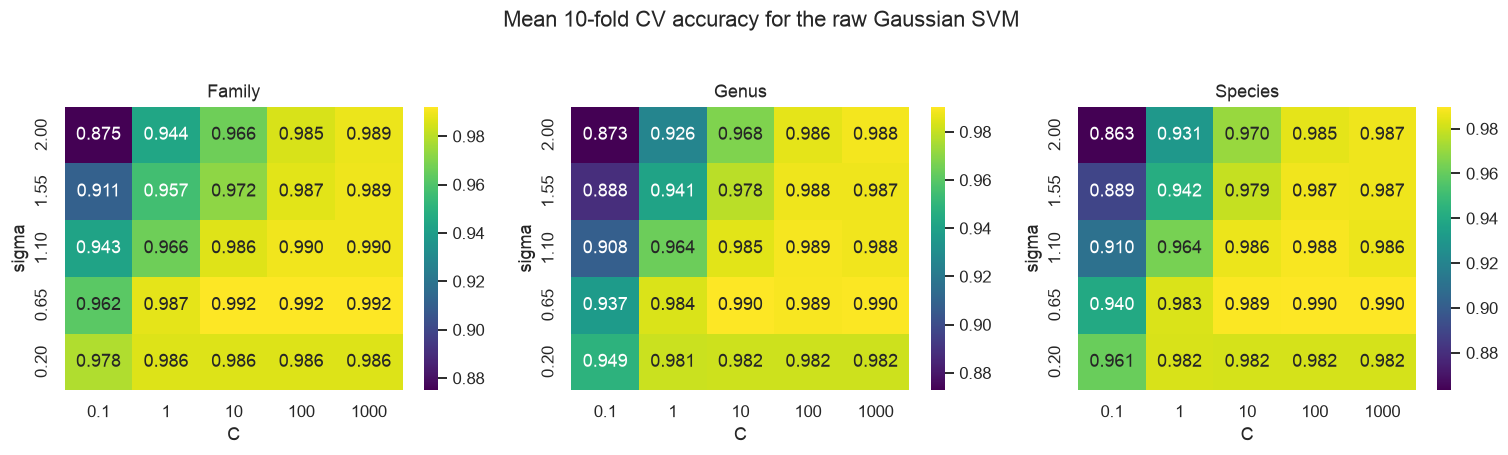

standardized Family: C=10, sigma=2.982, gamma=0.05623, CV accuracy=0.9919, 38.3s


standardized Genus: C=10, sigma=2.982, gamma=0.05623, CV accuracy=0.9909, 123.4s


standardized Species: C=10, sigma=2.982, gamma=0.05623, CV accuracy=0.9881, 141.8s

Selected standardized Gaussian hyperparameters


,C,gamma,sigma,mean_cv_accuracy
label,,,,
Family,10.0,0.0562,2.9818,0.9919
Genus,10.0,0.0562,2.9818,0.9909
Species,10.0,0.0562,2.9818,0.9881


Test metrics, standardized Gaussian one-vs-all SVM


,value
model,Gaussian standardized
exact_match,0.9866
hamming_distance,0.0306
hamming_score,0.9898
hamming_loss,0.0102
Family_accuracy,0.9926
Family_balanced_accuracy,0.9718
Genus_accuracy,0.9889
Genus_balanced_accuracy,0.9609
Species_accuracy,0.988


In [4]:
def sigma_from_gamma(gamma):
    return float(1.0 / np.sqrt(2.0 * gamma))


def gaussian_search(X_tr, y_tr, standardize):
    svc = SVC(kernel="rbf", cache_size=1000)
    if standardize:
        model = Pipeline(
            [
                ("scaler", StandardScaler()),
                ("clf", OneVsRestClassifier(svc)),
            ]
        )
        param_grid = {
            "clf__estimator__C": C_GRID,
            "clf__estimator__gamma": SCALED_GAMMA_GRID,
        }
        c_key, gamma_key = "clf__estimator__C", "clf__estimator__gamma"
    else:
        model = OneVsRestClassifier(svc)
        param_grid = {
            "estimator__C": C_GRID,
            "estimator__gamma": GAMMA_GRID,
        }
        c_key, gamma_key = "estimator__C", "estimator__gamma"
    search = GridSearchCV(
        model,
        param_grid,
        cv=CV,
        scoring="accuracy",
        n_jobs=-1,
        refit=True,
    )
    search.fit(X_tr, y_tr)
    rows = []
    for mean_score, params in zip(
        search.cv_results_["mean_test_score"], search.cv_results_["params"]
    ):
        gamma = params[gamma_key]
        rows.append(
            {
                "C": params[c_key],
                "gamma": gamma,
                "sigma": sigma_from_gamma(gamma),
                "mean_cv_accuracy": mean_score,
            }
        )
    table = pd.DataFrame(rows)
    return search, table


def best_gaussian_row(table):
    row = table.loc[table["mean_cv_accuracy"].idxmax()]
    return pd.Series(
        {
            "C": row["C"],
            "gamma": row["gamma"],
            "sigma": row["sigma"],
            "mean_cv_accuracy": row["mean_cv_accuracy"],
        }
    )


def training_accuracy_at_corners():
    corners = [
        (C_GRID[0], SIGMA_GRID[0]),
        (C_GRID[0], SIGMA_GRID[-1]),
        (C_GRID[-1], SIGMA_GRID[0]),
        (C_GRID[-1], SIGMA_GRID[-1]),
    ]
    records = []
    for label_index, label in enumerate(LABEL_COLS):
        y_tr = Y_train_np[:, label_index]
        for C, sigma in corners:
            clf = OneVsRestClassifier(
                SVC(kernel="rbf", C=C, gamma=1.0 / (2.0 * sigma**2), cache_size=1000)
            )
            clf.fit(X_train, y_tr)
            records.append(
                {
                    "label": label,
                    "C": C,
                    "sigma": sigma,
                    "training_accuracy": clf.score(X_train, y_tr),
                }
            )
    return pd.DataFrame(records)


print("Training accuracy at the four corners of the raw (C, sigma) grid")
corner_report = training_accuracy_at_corners()
display(corner_report)
below = corner_report.loc[corner_report["training_accuracy"] < 0.70]
if below.empty:
    print("Every corner is at or above the 70% training-accuracy threshold from the footnote.")
else:
    print("Corners below the 70% training-accuracy threshold are still inside the searched grid.")
    display(below)

raw_searches = {}
raw_tables = {}
raw_selected = []
raw_predictions = []
for label_index, label in enumerate(LABEL_COLS):
    started = time.perf_counter()
    search, table = gaussian_search(X_train, Y_train_np[:, label_index], standardize=False)
    elapsed = time.perf_counter() - started
    raw_searches[label] = search
    raw_tables[label] = table
    selected = best_gaussian_row(table).to_dict()
    selected["label"] = label
    raw_selected.append(selected)
    raw_predictions.append(search.predict(X_test))
    print(
        f"raw {label}: C={selected['C']:g}, sigma={selected['sigma']:.3f}, "
        f"CV accuracy={selected['mean_cv_accuracy']:.4f}, {elapsed:.1f}s"
    )

raw_selected = pd.DataFrame(raw_selected).set_index("label")
pred_gaussian_raw = np.column_stack(raw_predictions)
metrics_gaussian_raw = multilabel_report("Gaussian raw", Y_test_np, pred_gaussian_raw)

print()
print("Selected raw Gaussian hyperparameters")
display(raw_selected)
print("Test metrics, raw Gaussian one-vs-all SVM")
show_metrics(metrics_gaussian_raw)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, label in zip(axes, LABEL_COLS):
    pivot = raw_tables[label].pivot(index="sigma", columns="C", values="mean_cv_accuracy")
    pivot = pivot.sort_index(ascending=False)
    pivot.columns = [f"{value:g}" for value in pivot.columns]
    pivot.index = [f"{value:.2f}" for value in pivot.index]
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis", ax=ax)
    ax.set_title(label)
    ax.set_xlabel("C")
    ax.set_ylabel("sigma")
fig.suptitle("Mean 10-fold CV accuracy for the raw Gaussian SVM", y=1.03)
fig.tight_layout()
plt.show()

scaled_selected = []
scaled_predictions = []
for label_index, label in enumerate(LABEL_COLS):
    started = time.perf_counter()
    search, table = gaussian_search(X_train, Y_train_np[:, label_index], standardize=True)
    elapsed = time.perf_counter() - started
    selected = best_gaussian_row(table).to_dict()
    selected["label"] = label
    scaled_selected.append(selected)
    scaled_predictions.append(search.predict(X_test))
    print(
        f"standardized {label}: C={selected['C']:g}, sigma={selected['sigma']:.3f}, "
        f"gamma={selected['gamma']:.4g}, CV accuracy={selected['mean_cv_accuracy']:.4f}, {elapsed:.1f}s"
    )

scaled_selected = pd.DataFrame(scaled_selected).set_index("label")
pred_gaussian_scaled = np.column_stack(scaled_predictions)
metrics_gaussian_scaled = multilabel_report(
    "Gaussian standardized", Y_test_np, pred_gaussian_scaled
)

print()
print("Selected standardized Gaussian hyperparameters")
display(scaled_selected)
print("Test metrics, standardized Gaussian one-vs-all SVM")
show_metrics(metrics_gaussian_scaled)


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

The Gaussian model is replaced by an L1-penalized linear SVM. The usual pairing is an L1 penalty with a linear kernel, and `LinearSVC` already trains multi-class problems one versus all. Attributes are standardized inside each training fold. Only `C` is chosen, again by 10-fold stratified cross-validation on a log grid. The selected model is refit on the full training split.


L1 Family: C=1, CV accuracy=0.9378, 9.8s


L1 Genus: C=10, CV accuracy=0.9547, 18.6s


L1 Species: C=1, CV accuracy=0.9581, 18.9s

Selected L1-penalized linear SVM hyperparameters


,C,mean_cv_accuracy
label,,
Family,1.0,0.9378
Genus,10.0,0.9547
Species,1.0,0.9581


Test metrics, L1-penalized linear SVM


,value
model,L1 linear
exact_match,0.9176
hamming_distance,0.1579
hamming_score,0.9474
hamming_loss,0.0526
Family_accuracy,0.9333
Family_balanced_accuracy,0.6928
Genus_accuracy,0.9523
Genus_balanced_accuracy,0.8314
Species_accuracy,0.9565


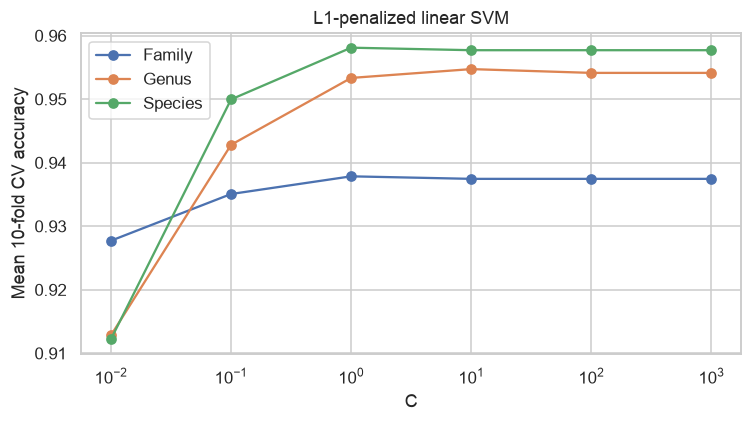

In [5]:
def l1_search(X_tr, y_tr, use_smote):
    svm = LinearSVC(
        penalty="l1",
        dual=False,
        max_iter=100000,
        random_state=RANDOM_STATE,
    )
    if use_smote:
        k_neighbors = max(1, min(5, int(np.floor(smallest_train_class * 0.9)) - 1))
        model = ImbPipeline(
            [
                ("scaler", StandardScaler()),
                ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=k_neighbors)),
                ("svm", svm),
            ]
        )
    else:
        model = Pipeline(
            [
                ("scaler", StandardScaler()),
                ("svm", svm),
            ]
        )
    search = GridSearchCV(
        model,
        {"svm__C": L1_C_GRID},
        cv=CV,
        scoring="accuracy",
        n_jobs=-1,
        refit=True,
    )
    search.fit(X_tr, y_tr)
    table = pd.DataFrame(
        {
            "C": np.asarray(search.cv_results_["param_svm__C"], dtype=float),
            "mean_cv_accuracy": search.cv_results_["mean_test_score"],
        }
    ).sort_values("C")
    return search, table


l1_curves = {}
l1_selected = []
l1_predictions = []
for label_index, label in enumerate(LABEL_COLS):
    started = time.perf_counter()
    search, table = l1_search(X_train, Y_train_np[:, label_index], use_smote=False)
    elapsed = time.perf_counter() - started
    l1_curves[label] = table
    l1_selected.append(
        {
            "label": label,
            "C": search.best_params_["svm__C"],
            "mean_cv_accuracy": search.best_score_,
        }
    )
    l1_predictions.append(search.predict(X_test))
    print(
        f"L1 {label}: C={search.best_params_['svm__C']:g}, "
        f"CV accuracy={search.best_score_:.4f}, {elapsed:.1f}s"
    )

l1_selected = pd.DataFrame(l1_selected).set_index("label")
pred_l1 = np.column_stack(l1_predictions)
metrics_l1 = multilabel_report("L1 linear", Y_test_np, pred_l1)

print()
print("Selected L1-penalized linear SVM hyperparameters")
display(l1_selected)
print("Test metrics, L1-penalized linear SVM")
show_metrics(metrics_l1)

fig, ax = plt.subplots(figsize=(7, 4))
for label in LABEL_COLS:
    curve = l1_curves[label]
    ax.plot(curve["C"], curve["mean_cv_accuracy"], marker="o", label=label)
ax.set_xscale("log")
ax.set_xlabel("C")
ax.set_ylabel("Mean 10-fold CV accuracy")
ax.set_title("L1-penalized linear SVM")
ax.legend()
fig.tight_layout()
plt.show()


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

The class counts in part (a) are badly unbalanced. `Bufonidae`, `Rhinella`, and `Rhinellagranulosa` each have 68 syllables, while the largest species has 3,478. This section repeats the L1 linear SVM, but SMOTE is fit on the training rows of each cross-validation fold after that fold's scaler is fit. The test rows are never oversampled, and the synthetic rows from one fold are not used to choose the scaler. `k_neighbors` is kept small enough for the smallest training class. `C` is chosen again by 10-fold cross-validation.


L1 + SMOTE Family: C=100, CV accuracy=0.9228, 37.2s


L1 + SMOTE Genus: C=1, CV accuracy=0.9174, 168.6s


L1 + SMOTE Species: C=0.1, CV accuracy=0.9551, 265.0s

Selected L1 + SMOTE hyperparameters


,C,mean_cv_accuracy
label,,
Family,100.0,0.9228
Genus,1.0,0.9174
Species,0.1,0.9551


Test metrics, L1-penalized linear SVM after SMOTE


,value
model,L1 linear + SMOTE
exact_match,0.862
hamming_distance,0.2246
hamming_score,0.9251
hamming_loss,0.0749
Family_accuracy,0.9134
Family_balanced_accuracy,0.9197
Genus_accuracy,0.9111
Genus_balanced_accuracy,0.8912
Species_accuracy,0.9509


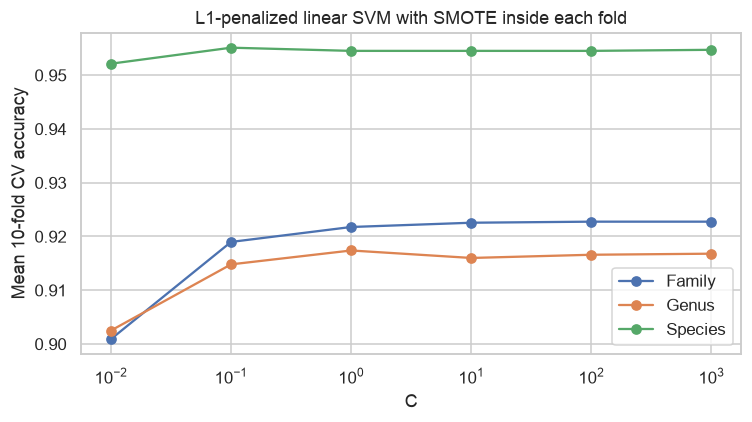

Test comparison of the four classifiers


,exact_match,hamming_distance,hamming_score,hamming_loss,Family_accuracy,Family_balanced_accuracy,Genus_accuracy,Genus_balanced_accuracy,Species_accuracy,Species_balanced_accuracy,mean_balanced_accuracy
model,,,,,,,,,,,
Gaussian raw,0.9838,0.0315,0.9895,0.0105,0.9907,0.9700,0.9903,0.9652,0.9875,0.9592,0.9648
Gaussian standardized,0.9866,0.0306,0.9898,0.0102,0.9926,0.9718,0.9889,0.9609,0.9880,0.9649,0.9658
L1 linear,0.9176,0.1579,0.9474,0.0526,0.9333,0.6928,0.9523,0.8314,0.9565,0.8881,0.8041
L1 linear + SMOTE,0.8620,0.2246,0.9251,0.0749,0.9134,0.9197,0.9111,0.8912,0.9509,0.9035,0.9048


Species recall on the test set, ordered from the smallest test class


,test_support,L1_recall,L1_SMOTE_recall
Rhinellagranulosa,20,0.8500,0.9000
OsteocephalusOophagus,27,0.6667,0.7778
ScinaxRuber,47,1.0000,0.9362
LeptodactylusFuscus,84,0.9048,0.9048
HylaMinuta,89,0.6517,0.8202
HypsiboasCinerascens,139,0.9640,0.9496
Ameeregatrivittata,158,0.9557,0.9241
AdenomeraAndre,203,0.9261,0.9015
HypsiboasCordobae,347,0.9654,0.9280
AdenomeraHylaedactylus,1045,0.9962,0.9933



The best test exact match is Gaussian standardized at 0.9866, with Hamming loss 0.0102 and Hamming score 0.9898.
Standardizing the MFCCs changes Gaussian exact match by less than one percentage point. The coefficients are already scaled into [-1, 1], so a second standardization does not move the decision boundary much.
The L1 linear SVM is less accurate than the Gaussian SVM on exact match and Hamming loss. A linear boundary does not separate these syllables as well as the RBF kernel.
SMOTE does not improve exact match, but it raises the average balanced accuracy from 0.8041 to 0.9048. Balanced accuracy gives the rare classes the same weight as the common ones. Exact match and Hamming loss are dominated by the common species, so moving a few errors from a rare class onto a common class does not look like a gain on those two scores. The average species-recall change from SMOTE is +0.0155.
Across all four models, Hamming score stays above exact match. Many remaining mistakes affect only

In [6]:
smote_curves = {}
smote_selected = []
smote_predictions = []
for label_index, label in enumerate(LABEL_COLS):
    started = time.perf_counter()
    search, table = l1_search(X_train, Y_train_np[:, label_index], use_smote=True)
    elapsed = time.perf_counter() - started
    smote_curves[label] = table
    smote_selected.append(
        {
            "label": label,
            "C": search.best_params_["svm__C"],
            "mean_cv_accuracy": search.best_score_,
        }
    )
    smote_predictions.append(search.predict(X_test))
    print(
        f"L1 + SMOTE {label}: C={search.best_params_['svm__C']:g}, "
        f"CV accuracy={search.best_score_:.4f}, {elapsed:.1f}s"
    )

smote_selected = pd.DataFrame(smote_selected).set_index("label")
pred_l1_smote = np.column_stack(smote_predictions)
metrics_l1_smote = multilabel_report("L1 linear + SMOTE", Y_test_np, pred_l1_smote)

print()
print("Selected L1 + SMOTE hyperparameters")
display(smote_selected)
print("Test metrics, L1-penalized linear SVM after SMOTE")
show_metrics(metrics_l1_smote)

fig, ax = plt.subplots(figsize=(7, 4))
for label in LABEL_COLS:
    curve = smote_curves[label]
    ax.plot(curve["C"], curve["mean_cv_accuracy"], marker="o", label=label)
ax.set_xscale("log")
ax.set_xlabel("C")
ax.set_ylabel("Mean 10-fold CV accuracy")
ax.set_title("L1-penalized linear SVM with SMOTE inside each fold")
ax.legend()
fig.tight_layout()
plt.show()

comparison = pd.DataFrame(
    [
        metrics_gaussian_raw,
        metrics_gaussian_scaled,
        metrics_l1,
        metrics_l1_smote,
    ]
).set_index("model")
print("Test comparison of the four classifiers")
display(comparison)

species_labels = list(pd.unique(Y_test_np[:, 2]))
species_support = pd.Series(Y_test_np[:, 2]).value_counts()
species_recall = pd.DataFrame(
    {
        "test_support": species_support,
        "L1_recall": recall_score(
            Y_test_np[:, 2],
            pred_l1[:, 2],
            labels=species_labels,
            average=None,
            zero_division=0,
        ),
        "L1_SMOTE_recall": recall_score(
            Y_test_np[:, 2],
            pred_l1_smote[:, 2],
            labels=species_labels,
            average=None,
            zero_division=0,
        ),
    },
    index=species_labels,
).sort_values("test_support")
print("Species recall on the test set, ordered from the smallest test class")
display(species_recall)

best_name = comparison["exact_match"].idxmax()
best = comparison.loc[best_name]
raw = comparison.loc["Gaussian raw"]
scaled = comparison.loc["Gaussian standardized"]
l1 = comparison.loc["L1 linear"]
smote = comparison.loc["L1 linear + SMOTE"]

print()
print(
    f"The best test exact match is {best_name} at {best['exact_match']:.4f}, "
    f"with Hamming loss {best['hamming_loss']:.4f} and Hamming score {best['hamming_score']:.4f}."
)
scale_gap = abs(raw["exact_match"] - scaled["exact_match"])
if scale_gap < 0.01:
    print(
        "Standardizing the MFCCs changes Gaussian exact match by less than one percentage point. "
        "The coefficients are already scaled into [-1, 1], so a second standardization does not move the decision boundary much."
    )
else:
    print(
        f"Standardizing the MFCCs changes Gaussian exact match from {raw['exact_match']:.4f} "
        f"to {scaled['exact_match']:.4f}."
    )
if l1["exact_match"] + 0.01 < max(raw["exact_match"], scaled["exact_match"]):
    print(
        "The L1 linear SVM is less accurate than the Gaussian SVM on exact match and Hamming loss. "
        "A linear boundary does not separate these syllables as well as the RBF kernel."
    )
else:
    print(
        "The L1 linear SVM is close to the Gaussian SVM on exact match. "
        "On this feature set the linear boundary already captures most of the label structure."
    )
recall_gain = float(
    (species_recall["L1_SMOTE_recall"] - species_recall["L1_recall"]).mean()
)
if smote["exact_match"] > l1["exact_match"] + 0.005:
    print(
        "SMOTE improves exact match relative to the L1 SVM fit on the original class frequencies."
    )
elif smote["mean_balanced_accuracy"] > l1["mean_balanced_accuracy"] + 0.01:
    print(
        "SMOTE does not improve exact match, but it raises the average balanced accuracy "
        f"from {l1['mean_balanced_accuracy']:.4f} to {smote['mean_balanced_accuracy']:.4f}. "
        "Balanced accuracy gives the rare classes the same weight as the common ones. "
        "Exact match and Hamming loss are dominated by the common species, so moving a few errors "
        "from a rare class onto a common class does not look like a gain on those two scores. "
        f"The average species-recall change from SMOTE is {recall_gain:+.4f}."
    )
else:
    print(
        "SMOTE does not improve exact match, Hamming loss, or average balanced accuracy relative to the plain L1 SVM. "
        "The linear model already sees enough rows from the smaller classes, or the synthetic syllables "
        "are not landing in a region that helps the test set. "
        f"The average species-recall change from SMOTE is {recall_gain:+.4f}."
    )
print(
    "Across all four models, Hamming score stays above exact match. "
    "Many remaining mistakes affect only one of the three labels, so a syllable can miss exact match while still contributing two correct labels to the Hamming score."
)


### Conclusions for part 1

On the 2,159 test syllables, the standardized Gaussian SVM has the best exact match, 0.9866, with Hamming score 0.9898 and Hamming loss 0.0102. The raw Gaussian SVM is within three thousandths on exact match (0.9838). The coefficients already lie in about [-1, 1], so standardizing them a second time barely moves the boundary. Cross-validation chooses sigma = 0.65 for every raw Gaussian label, with C = 100 for Family and Species and C = 10 for Genus. After standardization the selected penalty is C = 10 for every label, at gamma = 0.0562 (sigma about 2.98).

The L1 linear SVM is weaker: exact match 0.9176 and Hamming loss 0.0526. Its Family balanced accuracy is only 0.6928, so the linear boundary misses much of the rare families. SMOTE raises mean balanced accuracy from 0.8041 to 0.9048. Recall improves for the smallest species, including Rhinellagranulosa (0.85 to 0.90), OsteocephalusOophagus (0.67 to 0.78), and HylaMinuta (0.65 to 0.82). Exact match falls to 0.8620 and Hamming loss rises to 0.0749, because the extra correct rare-class predictions are paid for with more errors on the common classes. Exact match and Hamming loss are dominated by those common classes.

For every model, Hamming score is higher than exact match. A syllable with only one wrong label fails exact match and still contributes two correct labels to the Hamming score.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

Monte Carlo simulation: the procedure below is run 50 times. Each run selects `k`, fits K-means on the whole data set, replaces every syllable's labels by the majority Family, Genus, and Species of its cluster, and records the Hamming distance between those assigned labels and the true labels. The reported summary is the average and sample standard deviation of those 50 distances, together with the same summary for Hamming score and Hamming loss.

K-means is fit to all 7,195 syllables. There is no train/test split in this section, because the cluster assignment is unsupervised. The true labels are read only after the clusters have been formed, and only to name each cluster and to score it.

### (a) Use k-means clustering

`k` is chosen from `{2, 3, ..., 50}` by the maximum mean silhouette coefficient. `k = 1` is in the homework's range, but the silhouette compares within-cluster distance to the distance to the nearest other cluster, so it is undefined for a single cluster. Euclidean distance is used, matching the K-means objective. Each fit uses 10 random restarts (`n_init=10`); the Monte Carlo variation comes from changing the random seed between the 50 runs.

The next cell fits one clustering with a fixed seed and plots the silhouette curve used to choose `k`.


Illustrative run: selected k=4, silhouette=0.3853


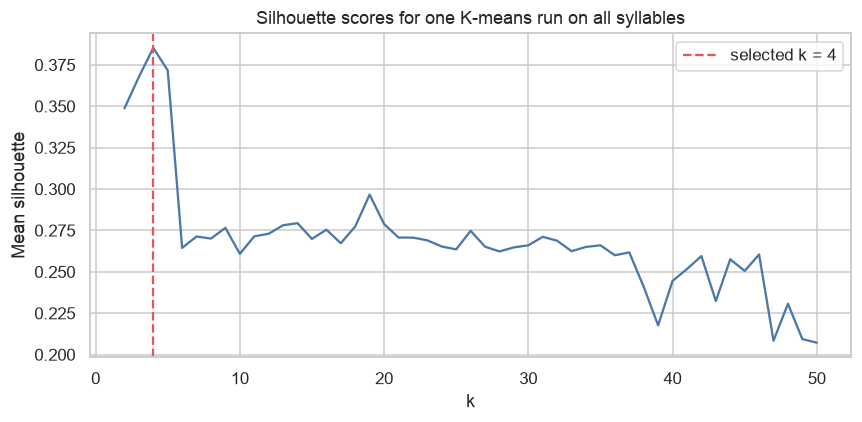

In [7]:
K_CANDIDATES = range(2, 51)


def labels_and_silhouette(k, seed):
    labels = KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(X)
    score = float(silhouette_score(X, labels))
    return k, score, labels


def select_k(seed, parallel):
    evaluated = parallel(
        delayed(labels_and_silhouette)(k, seed) for k in K_CANDIDATES
    )
    best_k, best_score, best_labels = max(evaluated, key=lambda item: item[1])
    curve = pd.DataFrame(
        {"k": [item[0] for item in evaluated], "silhouette": [item[1] for item in evaluated]}
    ).sort_values("k")
    return int(best_k), float(best_score), best_labels, curve


with Parallel(n_jobs=-1) as parallel:
    demo_k, demo_score, demo_labels, demo_curve = select_k(RANDOM_STATE, parallel)

print(f"Illustrative run: selected k={demo_k}, silhouette={demo_score:.4f}")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(demo_curve["k"], demo_curve["silhouette"], color="#4C78A8")
ax.axvline(demo_k, color="#E45756", linestyle="--", label=f"selected k = {demo_k}")
ax.set_xlabel("k")
ax.set_ylabel("Mean silhouette")
ax.set_title("Silhouette scores for one K-means run on all syllables")
ax.legend()
fig.tight_layout()
plt.show()


### (b) Determine which family is the majority

Inside each cluster, the majority Family is the label that occurs most often. The same count is done independently for Genus and Species. A tie goes to the label that appears first in `value_counts`, which sorts by count and then by order of appearance. The cluster's majority triplet is assigned to every syllable in that cluster, including syllables whose true label is not the majority.


In [8]:
def majority_table(cluster_labels):
    frame = Y.copy()
    frame["cluster"] = cluster_labels
    rows = []
    for cluster, group in frame.groupby("cluster"):
        row = {"cluster": int(cluster), "n": int(len(group))}
        for column in LABEL_COLS:
            counts = group[column].value_counts()
            row[column] = counts.index[0]
            row[f"{column}_share"] = float(counts.iloc[0] / len(group))
        rows.append(row)
    table = pd.DataFrame(rows).sort_values("cluster").reset_index(drop=True)
    return table


def labels_from_clusters(cluster_labels):
    table = majority_table(cluster_labels)
    lookup = {
        int(row.cluster): (row.Family, row.Genus, row.Species)
        for row in table.itertuples(index=False)
    }
    return np.array([lookup[int(cluster)] for cluster in cluster_labels], dtype=object), table


demo_pred, demo_majority = labels_from_clusters(demo_labels)
print(f"Majority label triplet for each cluster in the illustrative run (k={demo_k})")
display(demo_majority)
demo_metrics = multilabel_report("illustrative K-means", Y.to_numpy(), demo_pred)
print("Hamming summary for this single run, not the Monte Carlo average")
show_metrics(demo_metrics)


Majority label triplet for each cluster in the illustrative run (k=4)


,cluster,n,Family,Family_share,Genus,Genus_share,Species,Species_share
0,0,1819,Hylidae,0.4931,Hypsiboas,0.3222,HypsiboasCordobae,0.3222
1,1,3560,Leptodactylidae,0.9744,Adenomera,0.9736,AdenomeraHylaedactylus,0.9736
2,2,1104,Hylidae,0.9601,Hypsiboas,0.8569,HypsiboasCordobae,0.4475
3,3,712,Leptodactylidae,0.8258,Adenomera,0.5169,AdenomeraAndre,0.5169


Hamming summary for this single run, not the Monte Carlo average


,value
model,illustrative K-means
exact_match,0.683
hamming_distance,0.7354
hamming_score,0.7549
hamming_loss,0.2451
Family_accuracy,0.8359
Family_balanced_accuracy,0.4554
Genus_accuracy,0.7458
Genus_balanced_accuracy,0.2357
Species_accuracy,0.683


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

The illustrative run is not included in the average. The cell below repeats selection, clustering, majority assignment, and scoring 50 times with seeds `553, 554, ..., 602`. For each run, the Hamming distance is the average number of disagreeing labels per syllable. The mean and sample standard deviation (`ddof=1`) are then taken over the 50 run-level distances. Hamming score and Hamming loss are summarized in the same way.


run 01/50  k= 4  silhouette=0.3788  Hamming distance=0.6673


run 02/50  k= 4  silhouette=0.3788  Hamming distance=0.6673


run 03/50  k= 4  silhouette=0.3788  Hamming distance=0.6673


run 04/50  k= 4  silhouette=0.3788  Hamming distance=0.6673


run 05/50  k= 4  silhouette=0.3788  Hamming distance=0.6673


run 06/50  k= 4  silhouette=0.3853  Hamming distance=0.7354


... (44 outputs left out)


Mean and sample standard deviation over 50 runs


,k,hamming_distance,hamming_score,hamming_loss,exact_match
mean,4.0,0.6692,0.7769,0.2231,0.7536
std,0.0,0.0108,0.0036,0.0036,0.0110


Selected k across the 50 runs


,runs
k,
4,50


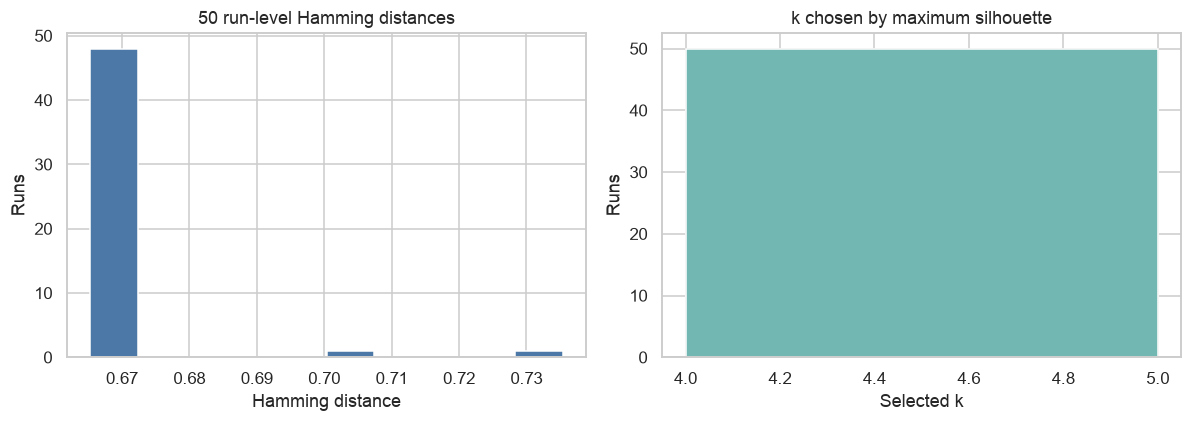

Average Hamming distance over 50 runs: 0.6692 (sample standard deviation 0.0108).
Average Hamming score: 0.7769 (sample standard deviation 0.0036).
Average Hamming loss: 0.2231 (sample standard deviation 0.0036).
These clustering scores are much weaker than the supervised SVM scores. K-means never sees the labels while it forms clusters, and the silhouette criterion keeps k far below the ten species. A cluster's single majority triplet therefore cannot name every species that fell into it, and Hamming loss stays large.


In [9]:
def one_replicate(run, parallel):
    seed = RANDOM_STATE + 1 + run
    chosen_k, chosen_score, cluster_labels, _curve = select_k(seed, parallel)
    predicted, _table = labels_from_clusters(cluster_labels)
    report = multilabel_report(f"run_{run + 1}", Y.to_numpy(), predicted)
    print(
        f"run {run + 1:02d}/50  k={chosen_k:2d}  silhouette={chosen_score:.4f}  "
        f"Hamming distance={report['hamming_distance']:.4f}",
        flush=True,
    )
    return {
        "run": run + 1,
        "k": chosen_k,
        "silhouette": chosen_score,
        "exact_match": report["exact_match"],
        "hamming_distance": report["hamming_distance"],
        "hamming_score": report["hamming_score"],
        "hamming_loss": report["hamming_loss"],
    }


with Parallel(n_jobs=-1) as parallel:
    monte_rows = [one_replicate(run, parallel) for run in range(50)]

monte = pd.DataFrame(monte_rows)
summary = monte[["k", "hamming_distance", "hamming_score", "hamming_loss", "exact_match"]].agg(
    ["mean", "std"]
)
print()
print("Mean and sample standard deviation over 50 runs")
display(summary)
print("Selected k across the 50 runs")
display(monte["k"].value_counts().sort_index().rename("runs").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(monte["hamming_distance"], bins=10, color="#4C78A8", edgecolor="white")
axes[0].set_xlabel("Hamming distance")
axes[0].set_ylabel("Runs")
axes[0].set_title("50 run-level Hamming distances")
axes[1].hist(monte["k"], bins=range(int(monte["k"].min()), int(monte["k"].max()) + 2), color="#72B7B2", edgecolor="white")
axes[1].set_xlabel("Selected k")
axes[1].set_ylabel("Runs")
axes[1].set_title("k chosen by maximum silhouette")
fig.tight_layout()
plt.show()

distance_mean = monte["hamming_distance"].mean()
distance_std = monte["hamming_distance"].std(ddof=1)
print(
    f"Average Hamming distance over 50 runs: {distance_mean:.4f} "
    f"(sample standard deviation {distance_std:.4f})."
)
print(
    f"Average Hamming score: {monte['hamming_score'].mean():.4f} "
    f"(sample standard deviation {monte['hamming_score'].std(ddof=1):.4f})."
)
print(
    f"Average Hamming loss: {monte['hamming_loss'].mean():.4f} "
    f"(sample standard deviation {monte['hamming_loss'].std(ddof=1):.4f})."
)
print(
    "These clustering scores are much weaker than the supervised SVM scores. "
    "K-means never sees the labels while it forms clusters, and the silhouette criterion "
    "keeps k far below the ten species. A cluster's single majority triplet therefore "
    "cannot name every species that fell into it, and Hamming loss stays large."
)


### Monte Carlo summary

All 50 runs select k = 4. The average Hamming distance is 0.6692, with sample standard deviation 0.0108. The average Hamming score is 0.7769 (standard deviation 0.0036) and the average Hamming loss is 0.2231 (standard deviation 0.0036). These are much weaker than the SVM scores. The clusters are formed without the labels, and four majority triplets cannot name all ten species.

## 3. ISLR 12.6.2

This is Exercise 2 of Chapter 12 in *An Introduction to Statistical Learning*, second edition. It does not use the frog data.

Suppose that we have four observations, for which we compute a dissimilarity matrix, given by

```
    0.3   0.4   0.7
          0.5   0.8
                0.45
```

For instance, the dissimilarity between the first and second observations is 0.3, and the dissimilarity between the second and fourth observations is 0.8.

The six pairwise dissimilarities are

- d(1, 2) = 0.3
- d(1, 3) = 0.4
- d(1, 4) = 0.7
- d(2, 3) = 0.5
- d(2, 4) = 0.8
- d(3, 4) = 0.45

**(a) Complete linkage.** At each step the two closest groups are fused, and the distance between groups is the maximum pairwise dissimilarity.

1. The closest pair is {1, 2}, fused at height 0.3.
2. The remaining distances are d({1, 2}, 3) = max(0.4, 0.5) = 0.5, d({1, 2}, 4) = max(0.7, 0.8) = 0.8, and d(3, 4) = 0.45. The smallest is 0.45, so {3, 4} fuses next.
3. The two groups fuse at max(0.4, 0.5, 0.7, 0.8) = 0.8.

**(b) Single linkage.** The distance between groups is the minimum pairwise dissimilarity.

1. {1, 2} still fuses first, at height 0.3.
2. d({1, 2}, 3) = min(0.4, 0.5) = 0.4, d({1, 2}, 4) = min(0.7, 0.8) = 0.7, and d(3, 4) = 0.45. The smallest is 0.4, so observation 3 joins {1, 2}.
3. Observation 4 then joins at min(0.7, 0.8, 0.45) = 0.45.

**(c)** Cutting the complete-linkage dendrogram into two clusters separates the last fusion, at height 0.8. The clusters are {1, 2} and {3, 4}.

**(d)** Cutting the single-linkage dendrogram into two clusters separates the last fusion, at height 0.45. The clusters are {1, 2, 3} and {4}.

**(e)** At every fusion, the left and right children can be swapped without changing which observations are grouped or the height of the fusion. Swapping leaves 1 and 2, and swapping leaves 3 and 4, gives the leaf order 2, 1, 4, 3. The fusion heights remain 0.3, 0.45, and 0.8, so this dendrogram has the same meaning as the one in (a).

The next cell draws these three dendrograms and prints the two-cluster cuts from the linkage matrices. The printed cuts match the hand calculation above.


Complete linkage matrix (observation indices are zero-based):
[[0.   1.   0.3  2.  ]
 [2.   3.   0.45 2.  ]
 [4.   5.   0.8  4.  ]]
Two complete-linkage clusters: {1: [1, 2], 2: [3, 4]}

Single linkage matrix:
[[0.   1.   0.3  2.  ]
 [2.   4.   0.4  3.  ]
 [3.   5.   0.45 4.  ]]
Two single-linkage clusters: {1: [1, 2, 3], 2: [4]}

Complete linkage after swapping leaves within each pair:
[[0.   1.   0.3  2.  ]
 [2.   3.   0.45 2.  ]
 [4.   5.   0.8  4.  ]]
Two clusters after swapping to leaf order 2, 1, 4, 3, labeled by the original observation numbers: {1: [1, 2], 2: [3, 4]}


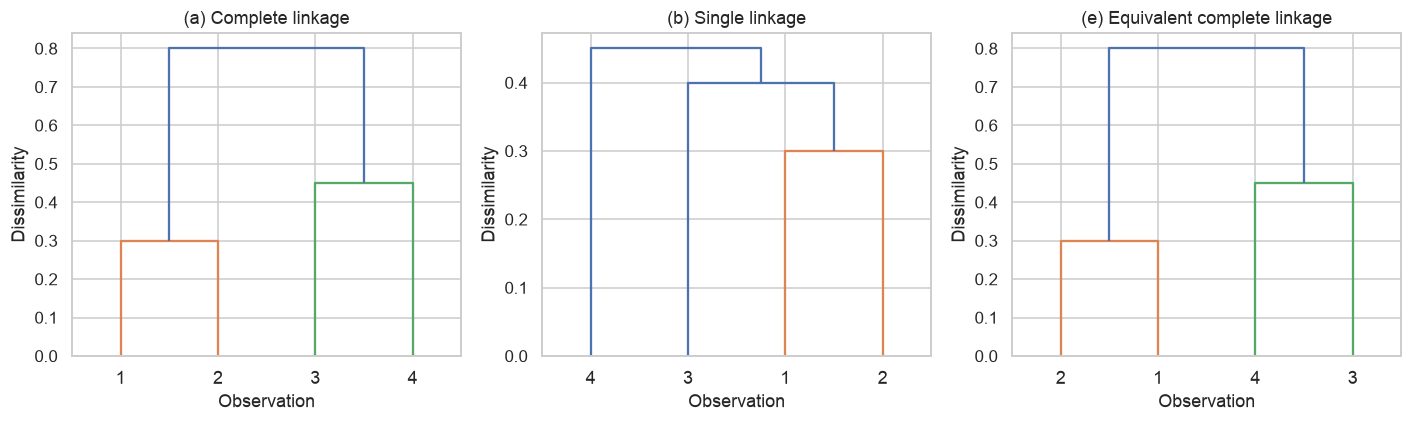

In [10]:
dissimilarity = np.array(
    [
        [0.0, 0.3, 0.4, 0.7],
        [0.3, 0.0, 0.5, 0.8],
        [0.4, 0.5, 0.0, 0.45],
        [0.7, 0.8, 0.45, 0.0],
    ]
)
condensed = squareform(dissimilarity)
complete = linkage(condensed, method="complete")
single = linkage(condensed, method="single")

swapped = [1, 0, 3, 2]
swapped_dissimilarity = dissimilarity[np.ix_(swapped, swapped)]
complete_swapped = linkage(squareform(swapped_dissimilarity), method="complete")

def groups_from_cut(link_matrix, names=None):
    assignment = fcluster(link_matrix, t=2, criterion="maxclust")
    grouped = {}
    for position, cluster in enumerate(assignment):
        name = position + 1 if names is None else names[position]
        grouped.setdefault(int(cluster), []).append(int(name))
    return {cluster: sorted(members) for cluster, members in grouped.items()}


print("Complete linkage matrix (observation indices are zero-based):")
print(complete)
print("Two complete-linkage clusters:", groups_from_cut(complete))
print()
print("Single linkage matrix:")
print(single)
print("Two single-linkage clusters:", groups_from_cut(single))
print()
print("Complete linkage after swapping leaves within each pair:")
print(complete_swapped)
print(
    "Two clusters after swapping to leaf order 2, 1, 4, 3, labeled by the original observation numbers:",
    groups_from_cut(complete_swapped, names=[2, 1, 4, 3]),
)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
dendrogram(complete, labels=["1", "2", "3", "4"], ax=axes[0])
axes[0].set_title("(a) Complete linkage")
axes[0].set_ylabel("Dissimilarity")
dendrogram(single, labels=["1", "2", "3", "4"], ax=axes[1])
axes[1].set_title("(b) Single linkage")
axes[1].set_ylabel("Dissimilarity")
dendrogram(complete_swapped, labels=["2", "1", "4", "3"], ax=axes[2])
axes[2].set_title("(e) Equivalent complete linkage")
axes[2].set_ylabel("Dissimilarity")
for ax in axes:
    ax.set_xlabel("Observation")
fig.tight_layout()
plt.show()


## References

- UCI Machine Learning Repository, Anuran Calls (MFCCs). The local file is the CSV distributed with that data set. The attribute and label description is in the data set readme.
- Sorower, M. S. (2010). *A Literature Survey on Algorithms for Multi-label Learning*. The exact-match and Hamming-loss definitions used in parts 1 and 2 follow that survey.
- James, G., Witten, D., Hastie, T., and Tibshirani, R. *An Introduction to Statistical Learning*, 2nd edition, Exercise 12.6.2.
- scikit-learn documentation for `SVC`, `LinearSVC`, `OneVsRestClassifier`, `GridSearchCV`, `KMeans`, `silhouette_score`, and `balanced_accuracy_score`.
- imbalanced-learn documentation for `SMOTE` and its pipeline, which applies the sampler only while fitting.
- Rousseeuw, P. J. (1987). Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics*.
